### YOLOv26

Yolov26 untersützt [End-to-End Detection](https://docs.ultralytics.com/guides/end2end-detection#how-end-to-end-detection-works). Das ist eine Technik, wo die Non-Maximum-Suppression bereits im Model passiert, und nicht im Postprocess noch angewendet werden muss. Zudem liefert YOLO anstatt der Koordinate mit Höhe und Breite direkt die jeweiligen Box-Koordinaten in dem Format [x1, y1, x2, y2] zurück.

Auch das manuelle herausfiltern von der Coco-Klasse mit der stärksten Confidence entfällt. Yolo liefert die zugehörige Coco-Class-Id hier auch zurück.



In [1]:
import numpy as np
import cv2 as cv

from yolo.utils.letterbox import letterbox

image: np.ndarray = cv.imread('pictures/bicycle.jpg')
resized, transform = letterbox(image)
blob = cv.dnn.blobFromImage(
    image=resized, scalefactor=1 / 255, size=(640, 640),
    swapRB=True, crop=False
)

# Load YOLO
net = cv.dnn.readNet('models/yolo26n.onnx')

# Put the blob into the input layer and receive the result from the output layer.
net.setInput(blob)
result = net.forward(net.getUnconnectedOutLayersNames())[0]
print(f"Output shape: {result.shape}")

# The 6 attributes are [x1, y1, x2, y2, confidence, class_id]
confidences = result[0, :, 4]
valid_confidences = confidences >= 0.5

print(f"{valid_confidences.sum()} valid detections")


Output shape: (1, 300, 6)
2 valid detections


#### Verarbeitung
Dank der End-to-End Detection ist die Nachbearbeitung deutlich einfacher.
- Yolo liefert direkt die erkannte Class-Id zurück, es muss keine Suche mehr mit np.argmax() gemacht werden.
- Es ist kein NMS nötig, das macht YOLO bereits automatisch
- Die Box wird von YOLO bereits mit 2 Koordinaten angegeben.



In [2]:
# [1, 300, 6]
# [x1, y1, x2, y2, confidence, class_id]
boxes = result[0, :, :4]
confidences = result[0, :, 4]
class_ids = result[0, :, 5]

mask = confidences > 0.5
print(f"{mask.sum()} valid detections")

boxes = boxes[mask, :]
confidences = confidences[mask]
class_ids = class_ids[mask]

# Resize

x1, y1 = boxes[:, 0], boxes[:, 1]
x2, y2 = boxes[:, 2], boxes[:, 3]
x1 = (x1 - transform.pad_x) / transform.scale
y1 = (y1 - transform.pad_y) / transform.scale
x2 = (x2 - transform.pad_x) / transform.scale
y2 = (y2 - transform.pad_y) / transform.scale

boxes = np.column_stack([x1, y1, x2, y2]).astype(int)

2 valid detections


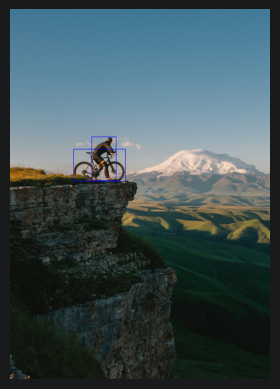

In [4]:
import matplotlib.pyplot as plt

# Draw

for box in boxes:
    x1, y1, x2, y2 = box
    cv.rectangle(img=image, pt1=(x1, y1), pt2=(x2, y2), color=(255, 0, 0), thickness=3)

# Transform BGR to RGB for matplotlib
canvas_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)
plt.imshow(canvas_rgb)
plt.axis("off")
plt.show()
